# Exploração dos dados da CVM (DFP 2021–2023)

Este notebook mostra a exploração que fiz antes de escrever o ETL (`src/etl.py`). Cada seção explica de onde veio uma regra da limpeza.

Para rodar: abrir a partir da pasta `notebooks/` com o ambiente do projeto e mais `pip install notebook matplotlib`. Na primeira vez os zips da CVM (uns 38 MB) são baixados para `data/bronze/zips/`.

## 1. Objetivo

- Entender o formato dos arquivos DFP (Demonstrações Financeiras Padronizadas) da CVM.
- Achar os problemas dos dados antes de calcular os indicadores: encoding, anos repetidos, versões, empresas que não se comparam e contas diferentes.
- Conferir um número da camada Gold com o número oficial publicado pela WEG.

In [1]:
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# o notebook roda de dentro de notebooks/, então o código do ETL está em ../src
sys.path.append("../src")
import etl

PASTA_DADOS = Path("../data")
pd.set_option("display.width", 150)


def bi(valor):
    # valor em reais -> texto em bilhões, com vírgula
    return f"R$ {valor / 1e9:.1f} bi".replace(".", ",")


print("pandas", pd.__version__)

pandas 3.0.6


## 2. Lendo um DFP: UTF-8 dá erro

A CVM publica um zip por ano. Dentro dele há um CSV por demonstrativo, separado por `;`. Usamos os consolidados (`_con_`): DRE, BPA (ativo) e BPP (passivo).

In [2]:
zips = etl.baixar_zips(PASTA_DADOS / "bronze" / "zips")
print([z.name for z in zips])

caminho_zip = zips[-1]  # 2023
with zipfile.ZipFile(caminho_zip) as arquivo_zip:
    consolidados = [nome for nome in arquivo_zip.namelist() if "_con_" in nome]
print(consolidados)

['dfp_cia_aberta_2021.zip', 'dfp_cia_aberta_2022.zip', 'dfp_cia_aberta_2023.zip']
['dfp_cia_aberta_BPA_con_2023.csv', 'dfp_cia_aberta_BPP_con_2023.csv', 'dfp_cia_aberta_DFC_MD_con_2023.csv', 'dfp_cia_aberta_DFC_MI_con_2023.csv', 'dfp_cia_aberta_DMPL_con_2023.csv', 'dfp_cia_aberta_DRA_con_2023.csv', 'dfp_cia_aberta_DRE_con_2023.csv', 'dfp_cia_aberta_DVA_con_2023.csv']


Primeira tentativa: ler com o padrão do pandas (UTF-8).

In [3]:
try:
    with zipfile.ZipFile(caminho_zip) as arquivo_zip:
        with arquivo_zip.open("dfp_cia_aberta_DRE_con_2023.csv") as arquivo:
            pd.read_csv(arquivo, sep=";", encoding="utf-8")
except UnicodeDecodeError as erro:
    print("Erro:", type(erro).__name__)
    print(erro)

Erro: UnicodeDecodeError
'utf-8' codec can't decode byte 0xe7 in position 232: invalid continuation byte


Forçar o UTF-8 trocando os bytes ruins também não serve: o `Ú` vira `�` e um filtro por `"ÚLTIMO"` não acha nada, sem dar erro nenhum.

In [4]:
with zipfile.ZipFile(caminho_zip) as arquivo_zip:
    with arquivo_zip.open("dfp_cia_aberta_DRE_con_2023.csv") as arquivo:
        dre_errado = pd.read_csv(arquivo, sep=";", encoding="utf-8", encoding_errors="replace", dtype=str)

print(dre_errado["ORDEM_EXERC"].unique().tolist())
print("linhas com ÚLTIMO:", (dre_errado["ORDEM_EXERC"] == "ÚLTIMO").sum())

['PEN�LTIMO', '�LTIMO']
linhas com ÚLTIMO: 0


Os arquivos estão em latin-1. Lendo assim (é o que a função `ler_demonstrativo` do ETL faz), os acentos ficam certos.

In [5]:
dre = etl.ler_demonstrativo(caminho_zip, "DRE", 2023)
print(dre.shape)
print(dre["ORDEM_EXERC"].unique().tolist())
print(dre.columns.tolist())

(33970, 15)
['PENÚLTIMO', 'ÚLTIMO']
['CNPJ_CIA', 'DT_REFER', 'VERSAO', 'DENOM_CIA', 'CD_CVM', 'GRUPO_DFP', 'MOEDA', 'ESCALA_MOEDA', 'ORDEM_EXERC', 'DT_INI_EXERC', 'DT_FIM_EXERC', 'CD_CONTA', 'DS_CONTA', 'VL_CONTA', 'ST_CONTA_FIXA']


In [6]:
# o valor vem como texto e a escala muda de empresa para empresa (MIL ou UNIDADE)
print(dre["ESCALA_MOEDA"].value_counts())
dre[["DENOM_CIA", "CD_CONTA", "DS_CONTA", "VL_CONTA"]].head(3)

ESCALA_MOEDA
MIL        33370
UNIDADE      600
Name: count, dtype: int64


,DENOM_CIA,CD_CONTA,DS_CONTA,VL_CONTA
0,BCO BRASIL S.A.,3.01,Receitas de Intermediação Financeira,236549051.0000000000
1,BCO BRASIL S.A.,3.01,Receitas de Intermediação Financeira,265438605.0000000000
2,BCO BRASIL S.A.,3.01.01,Receita de Juros,236549051.0000000000


**Regras que saíram daqui:** ler com `encoding="latin-1"`; `VL_CONTA` vira número e é multiplicado por 1000 quando a escala é `MIL`.

## 3. `ÚLTIMO` × `PENÚLTIMO` e versões reenviadas

A camada Bronze (`data/bronze/dfp_con_2021_2023.csv`) junta DRE, BPA e BPP dos três anos, só com as linhas das 11 empresas e do Itaú, sem mexer em nada.

In [7]:
bronze = pd.read_csv(PASTA_DADOS / "bronze" / "dfp_con_2021_2023.csv", dtype=str)
print(bronze.shape)
print("empresas:", bronze["CD_CVM"].nunique())
print(bronze["ORDEM_EXERC"].value_counts())

(16032, 16)
empresas: 12
ORDEM_EXERC
PENÚLTIMO    8016
ÚLTIMO       8016
Name: count, dtype: int64


Cada arquivo traz o ano do exercício (`ÚLTIMO`) e o ano anterior (`PENÚLTIMO`). A receita da WEG mostra isso: 2021 e 2022 aparecem duas vezes, uma em cada arquivo.

In [8]:
weg_receita = bronze[(bronze["CD_CVM"] == "005410") & (bronze["CD_CONTA"] == "3.01")]
weg_receita[["ARQUIVO_ORIGEM", "ORDEM_EXERC", "DT_FIM_EXERC", "VL_CONTA"]]

,ARQUIVO_ORIGEM,ORDEM_EXERC,DT_FIM_EXERC,VL_CONTA
688,dfp_cia_aberta_DRE_con_2021.csv,PENÚLTIMO,2020-12-31,17469557.0000000000
689,dfp_cia_aberta_DRE_con_2021.csv,ÚLTIMO,2021-12-31,23563338.0000000000
5992,dfp_cia_aberta_DRE_con_2022.csv,PENÚLTIMO,2021-12-31,23563338.0000000000
5993,dfp_cia_aberta_DRE_con_2022.csv,ÚLTIMO,2022-12-31,29904722.0000000000
11346,dfp_cia_aberta_DRE_con_2023.csv,PENÚLTIMO,2022-12-31,29904722.0000000000
11347,dfp_cia_aberta_DRE_con_2023.csv,ÚLTIMO,2023-12-31,32503601.0000000000


Ficamos só com o `ÚLTIMO` de cada arquivo (os números como foram publicados naquele ano). Assim cada empresa-ano aparece uma vez só.

Outra coisa: quando uma empresa corrige o DFP, ela reenvia e a `VERSAO` aumenta. Quatro empresas reenviaram:

In [9]:
reenviados = bronze[bronze["VERSAO"] != "1"]
print(reenviados.groupby(["DENOM_CIA", "DT_REFER"])["VERSAO"].unique())

# nos arquivos baixados cada empresa-ano tem uma versão só (a mais recente)
versoes = bronze.groupby(["CD_CVM", "DT_REFER"])["VERSAO"].nunique()
print("máximo de versões por empresa-ano:", versoes.max())

DENOM_CIA                           DT_REFER  
ENGIE BRASIL ENERGIA S.A.           2022-12-31    [2]
KLABIN S.A.                         2021-12-31    [3]
PETROLEO BRASILEIRO S.A. PETROBRAS  2023-12-31    [2]
VALE S.A.                           2022-12-31    [2]
Name: VERSAO, dtype: object


máximo de versões por empresa-ano: 1


Mesmo assim o ETL fica com a maior versão, caso o arquivo venha com mais de uma. Só que a `VERSAO` vem como texto, e texto se compara letra por letra:

In [10]:
print('max(["9", "10"]) =', max(["9", "10"]))
print("max([9, 10]) =", max([9, 10]))

max(["9", "10"]) = 9
max([9, 10]) = 10


**Regras que saíram daqui:** filtrar `ORDEM_EXERC == "ÚLTIMO"`; converter `VERSAO` para inteiro antes de pegar a maior.

## 4. O caso do Itaú

O enunciado sugere 12 empresas, entre elas o Itaú (ITUB4). Comparando os mesmos códigos de conta do Itaú e da WEG em 2023:

In [11]:
ultimo_2023 = bronze[(bronze["ORDEM_EXERC"] == "ÚLTIMO") & (bronze["DT_REFER"] == "2023-12-31")]
codigos = ["3.01", "1.01", "2.03", "2.08"]
comparacao = ultimo_2023[ultimo_2023["CD_CVM"].isin(["019348", "005410"]) & ultimo_2023["CD_CONTA"].isin(codigos)]
comparacao.pivot(index="CD_CONTA", columns="DENOM_CIA", values="DS_CONTA")

DENOM_CIA,ITAU UNIBANCO HOLDING S.A.,WEG S.A.
CD_CONTA,,
1.01,Caixa e Equivalentes de Caixa,Ativo Circulante
2.03,Passivos Financeiros ao Custo Amortizado,Patrimônio Líquido Consolidado
2.08,Patrimônio Líquido Consolidado,NaN
3.01,Receitas da Intermediação Financeira,Receita de Venda de Bens e/ou Serviços


Banco usa outro plano de contas: a conta 3.01 é receita de intermediação financeira, a 1.01 não é o ativo circulante e o patrimônio líquido fica na 2.08. Margens e liquidez corrente do Itaú não se comparam com as das outras empresas.

**Regra que saiu daqui:** o Itaú fica na Bronze (o dado bruto está lá) e sai na Silver. O painel compara 11 empresas.

## 5. Arrendamentos dentro da dívida

Desde a norma IFRS 16, aluguéis longos contam como dívida. No DFP existe a conta "Financiamento por Arrendamento" dentro de Empréstimos (2.01.04.03 no curto prazo e 2.02.01.03 no longo). Somando as duas, em R$ bi:

In [12]:
arrend = bronze[bronze["CD_CONTA"].isin(["2.01.04.03", "2.02.01.03"]) & (bronze["ORDEM_EXERC"] == "ÚLTIMO")].copy()
arrend["valor_bi"] = arrend["VL_CONTA"].astype(float) * 1000 / 1e9
arrend["ano"] = arrend["DT_REFER"].str[:4]
arrend.pivot_table(index="DENOM_CIA", columns="ano", values="valor_bi", aggfunc="sum").round(1)

ano,2021,2022,2023
DENOM_CIA,,,
AMBEV S.A.,0.0,0.0,0.0
EMBRAER S.A.,0.0,0.0,0.0
ENGIE BRASIL ENERGIA S.A.,0.0,0.0,0.0
GERDAU S.A.,0.0,0.0,0.0
JBS S.A.,0.0,0.0,0.0
KLABIN S.A.,0.0,0.0,0.0
LOJAS RENNER S.A.,0.0,0.0,0.0
PETROLEO BRASILEIRO S.A. PETROBRAS,128.6,124.4,163.6
SUZANO S.A.,0.0,0.0,0.0


Só a Petrobras e a Vale lançam valor nessa conta; as outras 9 deixam zerada. Se a dívida contasse esse valor, a Petrobras e a Vale pareceriam mais endividadas que as outras só por causa do jeito de lançar. Na Gold, a dívida líquida tira os arrendamentos:

In [13]:
fato = pd.read_csv(PASTA_DADOS / "gold" / "fato_indicadores.csv")
dim_empresa = pd.read_csv(PASTA_DADOS / "gold" / "dim_empresa.csv")
dim_tempo = pd.read_csv(PASTA_DADOS / "gold" / "dim_tempo.csv")
gold = fato.merge(dim_empresa, on="empresa_sk").merge(dim_tempo, on="tempo_sk")

petr = gold[(gold["ticker"] == "PETR4") & (gold["ano"] == 2023)].iloc[0]
print("Petrobras 2023 - dívida líquida sem arrendamentos:", bi(petr["divida_liquida"]))
print("Petrobras 2023 - dívida líquida com arrendamentos:", bi(petr["divida_liquida"] + petr["arrendamentos"]))

Petrobras 2023 - dívida líquida sem arrendamentos: R$ 64,2 bi
Petrobras 2023 - dívida líquida com arrendamentos: R$ 227,8 bi


**Regra que saiu daqui:** dívida líquida = empréstimos − arrendamentos − caixa − aplicações, igual para as 11 empresas.

## 6. Conferência da Gold com o release da WEG

No release de resultados do 4º trimestre de 2023, a WEG informa receita operacional líquida de R$ 32.503.601 mil no ano. A Gold está em reais:

In [14]:
weg = gold[gold["ticker"] == "WEGE3"].set_index("ano")
receita_release_mil = 32_503_601

receita_gold_mil = weg.loc[2023, "receita"] / 1000
print("receita 2023 na Gold (R$ mil):", f"{receita_gold_mil:,.0f}".replace(",", "."))
print("igual ao release:", receita_gold_mil == receita_release_mil)

receita 2023 na Gold (R$ mil): 32.503.601
igual ao release: True


O lucro precisa de cuidado: a manchete do release é o lucro dos controladores (R$ 5,73 bi em 2023). A conta 3.11 que usamos é o lucro consolidado, que inclui a parte dos acionistas minoritários, então fica um pouco maior (R$ 5,87 bi).

In [15]:
lucro_2023 = weg.loc[2023, "lucro_liquido"]
print("lucro consolidado 2023:", f"R$ {lucro_2023 / 1e9:.2f} bi".replace(".", ","))
weg[["receita", "lucro_liquido", "patrimonio_liquido"]].map(bi)

lucro consolidado 2023: R$ 5,87 bi


,receita,lucro_liquido,patrimonio_liquido
ano,,,
2021,"R$ 23,6 bi","R$ 3,7 bi","R$ 14,0 bi"
2022,"R$ 29,9 bi","R$ 4,3 bi","R$ 15,2 bi"
2023,"R$ 32,5 bi","R$ 5,9 bi","R$ 17,9 bi"


## 7. Primeiros gráficos

Antes do app, dois gráficos rápidos para ver se os números faziam sentido. A WEG em azul e as outras em cinza, como depois ficou no painel.

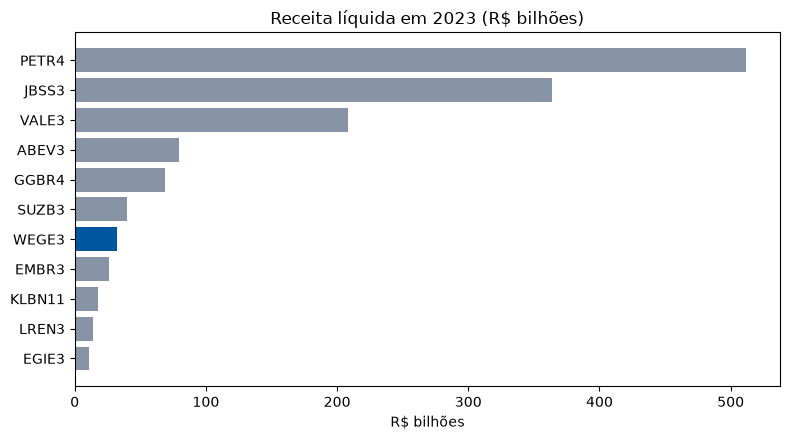

In [16]:
r2023 = gold[gold["ano"] == 2023].sort_values("receita")
cores = ["#00579D" if t == "WEGE3" else "#8794A6" for t in r2023["ticker"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(r2023["ticker"], r2023["receita"] / 1e9, color=cores)
ax.set_title("Receita líquida em 2023 (R$ bilhões)")
ax.set_xlabel("R$ bilhões")
plt.tight_layout()
plt.show()

A WEG tem receita bem menor que a Petrobras, a JBS e a Vale. Por isso, para comparar empresas de tamanhos tão diferentes, faz mais sentido olhar margens e crescimento em %.

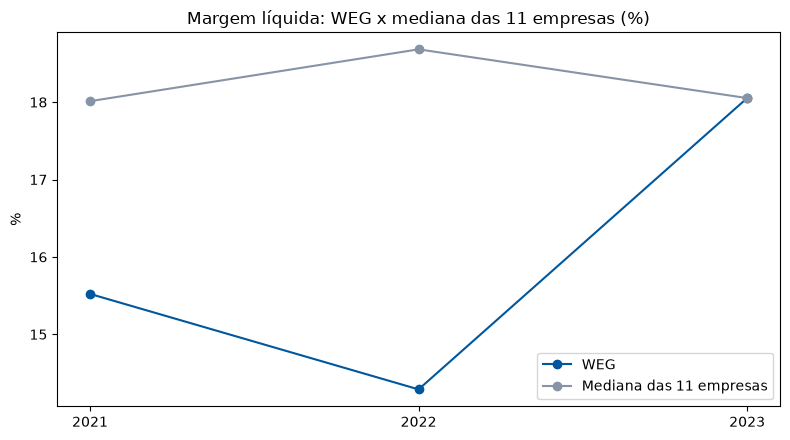

       WEG  mediana
ano                
2021  15.5     18.0
2022  14.3     18.7
2023  18.1     18.1


In [17]:
mediana = gold.groupby("ano")["margem_liquida"].median() * 100
margem_weg = weg["margem_liquida"] * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(margem_weg.index, margem_weg.values, marker="o", color="#00579D", label="WEG")
ax.plot(mediana.index, mediana.values, marker="o", color="#8794A6", label="Mediana das 11 empresas")
ax.set_xticks([2021, 2022, 2023])
ax.set_title("Margem líquida: WEG x mediana das 11 empresas (%)")
ax.set_ylabel("%")
ax.legend()
plt.tight_layout()
plt.show()

print(pd.DataFrame({"WEG": margem_weg.round(1), "mediana": mediana.round(1)}))

## Resumo: o que foi para o ETL

1. Ler os CSVs da CVM com `encoding="latin-1"`.
2. Ficar com o `ÚLTIMO` de cada arquivo.
3. Ficar com a maior `VERSAO`, convertida para inteiro.
4. Tirar o Itaú na Silver (plano de contas de banco).
5. Usar só as contas dos indicadores e converter o valor para reais (escala `MIL` × 1000).
6. Dívida líquida sem os arrendamentos, para comparar igual.
7. Conferir a Gold com um número oficial: a receita da WEG em 2023 bate com o release.